# 04 · What did the agent learn?

The agent was never shown a strategy, only wins and losses. Here it is compared with the strategies it trained against: does it play like one of them, or has it found something of its own?

Data: `results/evaluation.json`, `results/style.json`, `results/raw/agent_games.parquet` (`python -m catanbot.pipeline evaluate|style --checkpoint ...`).

In [1]:
import json
from pathlib import Path
import numpy as np
import polars as pl
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RESULTS = ROOT / "results"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25})
COLORS = {"balanced": "#2a6f97", "ows": "#7d5ba6", "road_builder": "#b5532f", "dev_rush": "#3c8d5a",
          "port_master": "#c9962b", "greedy": "#8a8f98", "random": "#b8bcc4", "learned": "#d1495b"}
LABELS = {"balanced": "Balanced", "ows": "Ore-Wheat-Sheep", "road_builder": "Road Builder",
          "dev_rush": "Dev-Card Rush", "port_master": "Port Master", "learned": "Learned (RL)"}

ev = json.loads((RESULTS / 'evaluation.json').read_text())
style = json.loads((RESULTS / 'style.json').read_text())
agent = pl.read_parquet(RESULTS / 'raw' / 'agent_games.parquet')
bots = pl.read_parquet(RESULTS / 'raw' / 'tournament.parquet')

## Final evaluation
The agent in one seat and three tuned strategy bots in the others, all seats rotated. The baseline is the strongest strategy bot sitting in the agent's seat against the same opponents.

In [2]:
rows = [{'opponents': ', '.join(LABELS[t] for t in e['table']), 'games': e['games'], 'agent': e['win_rate'],
         'ci': f"{e['ci_low']:.1%}-{e['ci_high']:.1%}", 'baseline bot': LABELS[e['baseline']['bot']],
         'baseline': e['baseline']['win_rate']} for e in ev]
pl.DataFrame(rows)

opponents,games,agent,ci,baseline bot,baseline
str,i64,f64,str,str,f64
"""Balanced, Ore-Wheat-Sheep, Roa…",40448,0.241372,"""23.7%-24.6%""","""Balanced""",0.28255
"""Balanced, Ore-Wheat-Sheep, Dev…",4096,0.232422,"""22.0%-24.6%""","""Balanced""",0.356
"""Balanced, Ore-Wheat-Sheep, Por…",4096,0.247803,"""23.5%-26.1%""","""Balanced""",0.324
"""Balanced, Road Builder, Dev-Ca…",4096,0.241699,"""22.9%-25.5%""","""Balanced""",0.30225
"""Balanced, Road Builder, Port M…",4096,0.300537,"""28.7%-31.5%""","""Balanced""",0.35875
"""Balanced, Dev-Card Rush, Port …",4096,0.24585,"""23.3%-25.9%""","""Balanced""",0.34725
"""Ore-Wheat-Sheep, Road Builder,…",4096,0.228516,"""21.6%-24.2%""","""Balanced""",0.3265
"""Ore-Wheat-Sheep, Road Builder,…",4096,0.275635,"""26.2%-29.0%""","""Balanced""",0.334
"""Ore-Wheat-Sheep, Dev-Card Rush…",4096,0.296631,"""28.3%-31.1%""","""Balanced""",0.42675


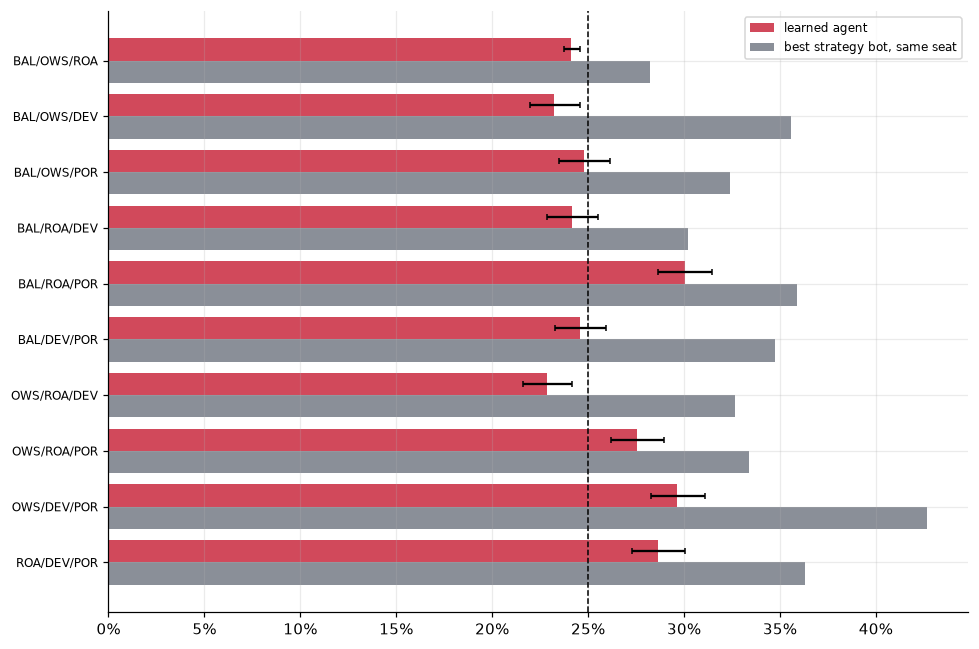

In [3]:
fig, ax = plt.subplots(figsize=(9, 0.5 * len(ev) + 1))
y = np.arange(len(ev))[::-1]
ax.barh(y + 0.2, [e['win_rate'] for e in ev], 0.4, color=COLORS['learned'], label='learned agent',
        xerr=[[e['win_rate'] - e['ci_low'] for e in ev], [e['ci_high'] - e['win_rate'] for e in ev]], capsize=2)
ax.barh(y - 0.2, [e['baseline']['win_rate'] for e in ev], 0.4, color='#8a8f98', label='best strategy bot, same seat')
ax.set_yticks(y, ['/'.join(t[:3].upper() for t in e['table']) for e in ev], fontsize=8)
ax.axvline(0.25, color='k', ls='--', lw=1); ax.xaxis.set_major_formatter(lambda v, _: f'{v:.0%}'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## Play style vs. the strategies

In [4]:
pl.DataFrame(style['rows'], infer_schema_length=None)

bot,win_rate,opening_ore_wheat,opening_wood_brick,opening_port,settlements,cities,roads,dev_bought,trades,longest_road,largest_army,first_city_turn
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""learned""",0.249023,0.444175,0.331595,0.136963,1.41687,1.639771,6.276978,7.015381,5.875244,0.07019,0.504883,35.054567
"""balanced""",0.376428,0.398497,0.425339,0.202191,3.163274,1.898075,8.796728,1.730917,6.559163,0.289945,0.02995,42.119604
"""ows""",0.28659,0.669841,0.156512,0.236627,0.562759,2.486472,4.375959,5.938284,6.381954,0.012334,0.362316,23.843168
"""road_builder""",0.229294,0.171754,0.67812,0.208683,3.955308,0.912561,9.625185,0.777652,6.399954,0.71464,0.004061,56.421727
"""dev_rush""",0.202587,0.497332,0.127196,0.228221,0.771922,1.688041,3.207097,7.812136,6.487654,0.00161,0.615478,29.557204
"""port_master""",0.155141,0.33666,0.431129,0.667541,3.034597,1.471939,7.759123,0.943674,9.127432,0.18968,0.009382,43.769747


## Opening choices
Production (in pips) per resource right after the two setup settlements.

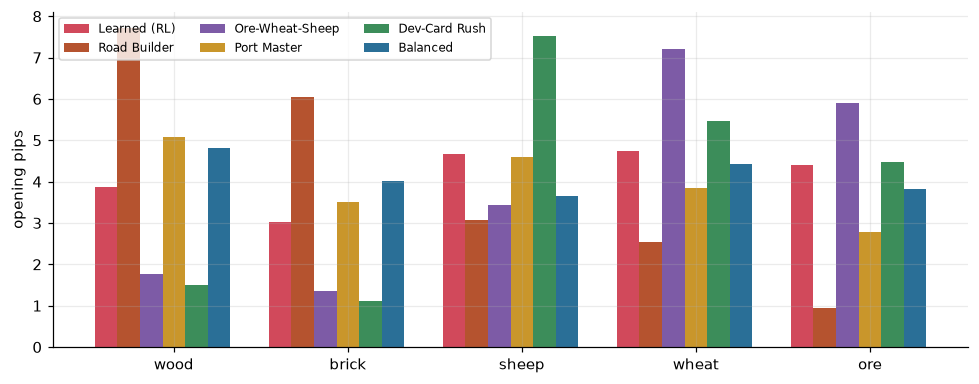

In [5]:
res = ['wood', 'brick', 'sheep', 'wheat', 'ore']
def opening(df):
    o = df.group_by('bot').agg([pl.col(f'opening_{r}').mean().alias(r) for r in res])
    return o
o = pl.concat([opening(agent.filter(pl.col('bot') == 'learned')), opening(bots)])
fig, ax = plt.subplots(figsize=(9, 3.6))
w = 0.13
for i, r in enumerate(o.iter_rows(named=True)):
    ax.bar(np.arange(5) + (i - len(o) / 2) * w, [r[x] for x in res], w, label=LABELS.get(r['bot'], r['bot']), color=COLORS.get(r['bot']))
ax.set_xticks(range(5), res); ax.set_ylabel('opening pips'); ax.legend(fontsize=8, ncol=3)
plt.tight_layout(); plt.show()

## Does the agent adapt its plan to the board?
If the agent follows one fixed strategy, its opening resource mix should barely vary. If it adapts, the mix should follow what the board offers. Below: the distribution of the ore+wheat share of the agent's opening production, compared with Ore-Wheat-Sheep and Road Builder.

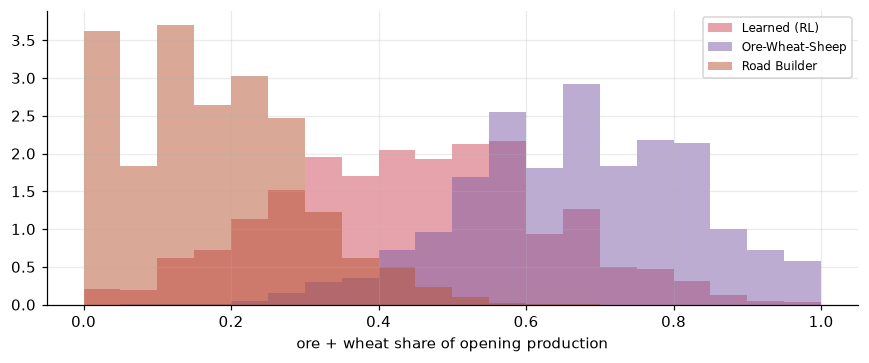

In [6]:
def share(df):
    tot = sum(pl.col(f'opening_{r}') for r in res)
    return df.with_columns(((pl.col('opening_ore') + pl.col('opening_wheat')) / tot).alias('ow'))
fig, ax = plt.subplots(figsize=(8, 3.4))
for name, d in [('learned', share(agent.filter(pl.col('bot') == 'learned'))), ('ows', share(bots.filter(pl.col('bot') == 'ows'))),
                ('road_builder', share(bots.filter(pl.col('bot') == 'road_builder')))]:
    ax.hist(d['ow'].drop_nulls().to_numpy(), bins=20, range=(0, 1), alpha=0.5, density=True, label=LABELS[name], color=COLORS[name])
ax.set_xlabel('ore + wheat share of opening production'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## How the agent's wins are built

In [7]:
aw = agent.filter((pl.col('bot') == 'learned') & (pl.col('won') == 1))
aw.select([pl.col('settlements').mean(), (2 * pl.col('cities')).mean().alias('city VP'),
           (2 * pl.col('longest_road')).mean().alias('LR VP'), (2 * pl.col('largest_army')).mean().alias('LA VP'),
           pl.col('vp_cards').mean(), pl.col('dev_bought').mean(), pl.col('trades').mean(), pl.col('turns').mean()])

settlements,city VP,LR VP,LA VP,vp_cards,dev_bought,trades,turns
f64,f64,f64,f64,f64,f64,f64,f64
1.325,4.838235,0.326471,1.546078,2.018627,8.517157,6.569608,77.055392
